# Models & Comparison
## Reddit Sentiment Analysis — 2024 US Presidential Election

**Pipeline:** `Data_preparation` → `VADER_Labeling` → **`Models`** → `Sentiment_Analysis`

| Section | Content |
|---------|---------|
| 0–3 | Imports, data, preprocessing, BoW sample |
| 4 | Bag-of-Words — train / evaluate / temporal |
| 5 | 12k Candidate Basis — build once, evaluate all models on it |
| 6 | RoBERTa — inference on 12k basis + 50k temporal |
| 7 | GPT-4o-mini — inference on 12k basis |
| 8 | Save combined parquet (all 4 labels) |
| 9–15 | Comprehensive comparison across all models |

## 0. Imports & Setup

In [60]:
import warnings
warnings.filterwarnings('ignore')

import re, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, cohen_kappa_score
)

BASE_DIR    = Path('..').resolve()
DATA_DIR    = BASE_DIR / 'Datasources'
RESULTS_DIR = DATA_DIR / 'model_results'
RESULTS_DIR.mkdir(exist_ok=True)

plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.family'] = 'sans-serif'
sns.set_style('whitegrid')

LABEL_ORDER  = ['positive', 'neutral', 'negative']
LABEL_COLORS = {'positive': '#2ca02c', 'neutral': '#aec7e8', 'negative': '#d62728'}
MONTHS_ORDER = ['June', 'July', 'August', 'September', 'October', 'November']
MONTH_MID    = {
    'June': '2024-06-15', 'July': '2024-07-15', 'August': '2024-08-15',
    'September': '2024-09-15', 'October': '2024-10-15', 'November': '2024-11-03',
}
EVENTS = {
    '2024-06-27': 'Biden-Trump debate',
    '2024-07-13': 'Trump assassination attempt',
    '2024-07-21': 'Biden drops out',
    '2024-08-06': 'Walz VP pick',
    '2024-09-10': 'Harris-Trump debate',
    '2024-10-01': 'Walz-Vance VP debate',
    '2024-10-05': '2nd assassination attempt',
    '2024-11-05': 'Election Day',
}
MODELS      = ['bow_label', 'rob_label', 'gpt_label']
MODEL_NAMES = ['BoW (TF-IDF+LR)', 'RoBERTa', 'GPT-4o-mini']
MODEL_COLORS= ['#2ca02c', '#9467bd', '#ff7f0e']
RANDOM_STATE = 42

print('Setup complete.')

Setup complete.


## 1. Load Data
Load the full VADER-labelled corpus produced by `VADER_Labeling.ipynb`.

In [61]:
df = pd.read_parquet(DATA_DIR / 'df_comments_vader.parquet')
df['date']     = pd.to_datetime(df['date'])
df['date_day'] = pd.to_datetime(df['date_day'])
print(f'Total comments : {len(df):,}')
print(f'Date range     : {df["date"].min().date()} → {df["date"].max().date()}')
print()
print('VADER label distribution:')
for label, n in df['vader_label'].value_counts().items():
    print(f'  {label:10s}: {n:,}  ({n/len(df)*100:.1f}%)')

Total comments : 6,633,771
Date range     : 2024-06-01 → 2024-11-06

VADER label distribution:
  positive  : 2,674,630  (40.3%)
  negative  : 2,390,622  (36.0%)
  neutral   : 1,568,519  (23.6%)


## 2. Text Preprocessing

Two cleaning functions used throughout the notebook:
- **`clean_text`** — aggressive (BoW): lowercase, strip URLs/markdown/punctuation
- **`clean_text_roberta`** — light (RoBERTa / GPT): preserve casing & punctuation, replace URLs only

In [62]:
def clean_text(text: str) -> str:
    text = str(text).lower()
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'/r/\w+|/u/\w+|u/\w+', '', text)
    text = re.sub(r'&amp;|&lt;|&gt;|&quot;', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def clean_text_roberta(text: str) -> str:
    text = str(text)
    text = re.sub(r'http\S+|www\.\S+', '[URL]', text)
    text = re.sub(r'/r/\w+|/u/\w+|u/\w+', '', text)
    text = re.sub(r'&amp;|&lt;|&gt;|&quot;', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

print('Preprocessing functions defined.')

Preprocessing functions defined.


## 3. Sample & Split
Stratified 80k sample for BoW training, 80/20 split.
RoBERTa and GPT are evaluated directly on the 12k candidate basis (Section 5).

In [ ]:
SAMPLE_SIZE = 80_000

df_sample = (
    df.groupby('vader_label', group_keys=False)
    .apply(lambda g: g.sample(
        min(len(g), int(SAMPLE_SIZE * len(g) / len(df))),
        random_state=RANDOM_STATE
    ))
)
df_sample['text_clean'] = df_sample['body'].apply(clean_text)
df_sample = df_sample[df_sample['text_clean'].str.strip().str.len() > 5]

X = df_sample['text_clean'].values
y = df_sample['vader_label'].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f'Sample : {len(df_sample):,}  |  Train: {len(X_train):,}  |  Test: {len(X_test):,}')

## 4. Approach 1 — Bag-of-Words (TF-IDF + Logistic Regression)

**Checkpoint:** `model_results/bow_checkpoint.joblib`  
Loads instantly if present; trains (~2 min) on first run.

### 4.1 Train or Load

In [74]:
_BOW_CKPT = RESULTS_DIR / 'bow_checkpoint.joblib'

if _BOW_CKPT.exists():
    ckpt       = joblib.load(_BOW_CKPT)
    tfidf      = ckpt['tfidf']
    lr         = ckpt['lr']
    y_pred     = ckpt['y_pred']
    y_test     = ckpt['y_test']
    bow_acc    = ckpt['bow_acc']
    bow_f1_mac = ckpt['bow_f1_mac']
    bow_f1_wei = ckpt['bow_f1_wei']
    print(f'✓ BoW checkpoint loaded')
    print(f'  Accuracy   : {bow_acc:.4f}')
    print(f'  Macro F1   : {bow_f1_mac:.4f}')
    print(f'  Weighted F1: {bow_f1_wei:.4f}')
else:
    print('No checkpoint found — training BoW model...')
    tfidf = TfidfVectorizer(
        max_features=60_000, ngram_range=(1, 2),
        sublinear_tf=True, min_df=3
    )
    X_tr = tfidf.fit_transform(X_train)
    X_te = tfidf.transform(X_test)
    print(f'  Vocabulary size: {len(tfidf.vocabulary_):,}')
    lr = LogisticRegression(
        max_iter=1000, C=1.0, solver='lbfgs',
        multi_class='multinomial', random_state=RANDOM_STATE
    )
    lr.fit(X_tr, y_train)
    y_pred     = lr.predict(X_te)
    bow_acc    = accuracy_score(y_test, y_pred)
    bow_f1_mac = f1_score(y_test, y_pred, average='macro',    labels=LABEL_ORDER)
    bow_f1_wei = f1_score(y_test, y_pred, average='weighted', labels=LABEL_ORDER)
    joblib.dump({
        'tfidf': tfidf, 'lr': lr, 'y_pred': y_pred, 'y_test': y_test,
        'bow_acc': bow_acc, 'bow_f1_mac': bow_f1_mac, 'bow_f1_wei': bow_f1_wei,
    }, _BOW_CKPT)
    print(f'  Accuracy   : {bow_acc:.4f}')
    print(f'  Macro F1   : {bow_f1_mac:.4f}')
    print(f'  Weighted F1: {bow_f1_wei:.4f}')
    print(f'✓ BoW checkpoint saved → {_BOW_CKPT}')

    print(classification_report(y_test, y_pred, target_names=LABEL_ORDER, digits=4))
    cm      = confusion_matrix(y_test, y_pred, labels=LABEL_ORDER)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle('BoW — Confusion Matrix (80k train / 20k test)', fontweight='bold')
    for ax, mat, title, fmt in [
        (axes[0], cm,      'Counts',          'd'),
        (axes[1], cm_norm, 'Row-normalised',  '.2f'),
    ]:
        sns.heatmap(mat, annot=True, fmt=fmt, ax=ax,
                    xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER,
                    cmap='Blues', linewidths=0.5, vmin=0, vmax=None if fmt=='d' else 1)
        ax.set_title(title); ax.set_xlabel('Predicted'); ax.set_ylabel('True (VADER)')
    plt.tight_layout(); plt.show()

✓ BoW checkpoint loaded
  Accuracy   : 0.7880
  Macro F1   : 0.7867
  Weighted F1: 0.7883


### 4.3 Feature Importance — Top Words per Class
Logistic Regression coefficients — which n-grams most strongly predict each sentiment.

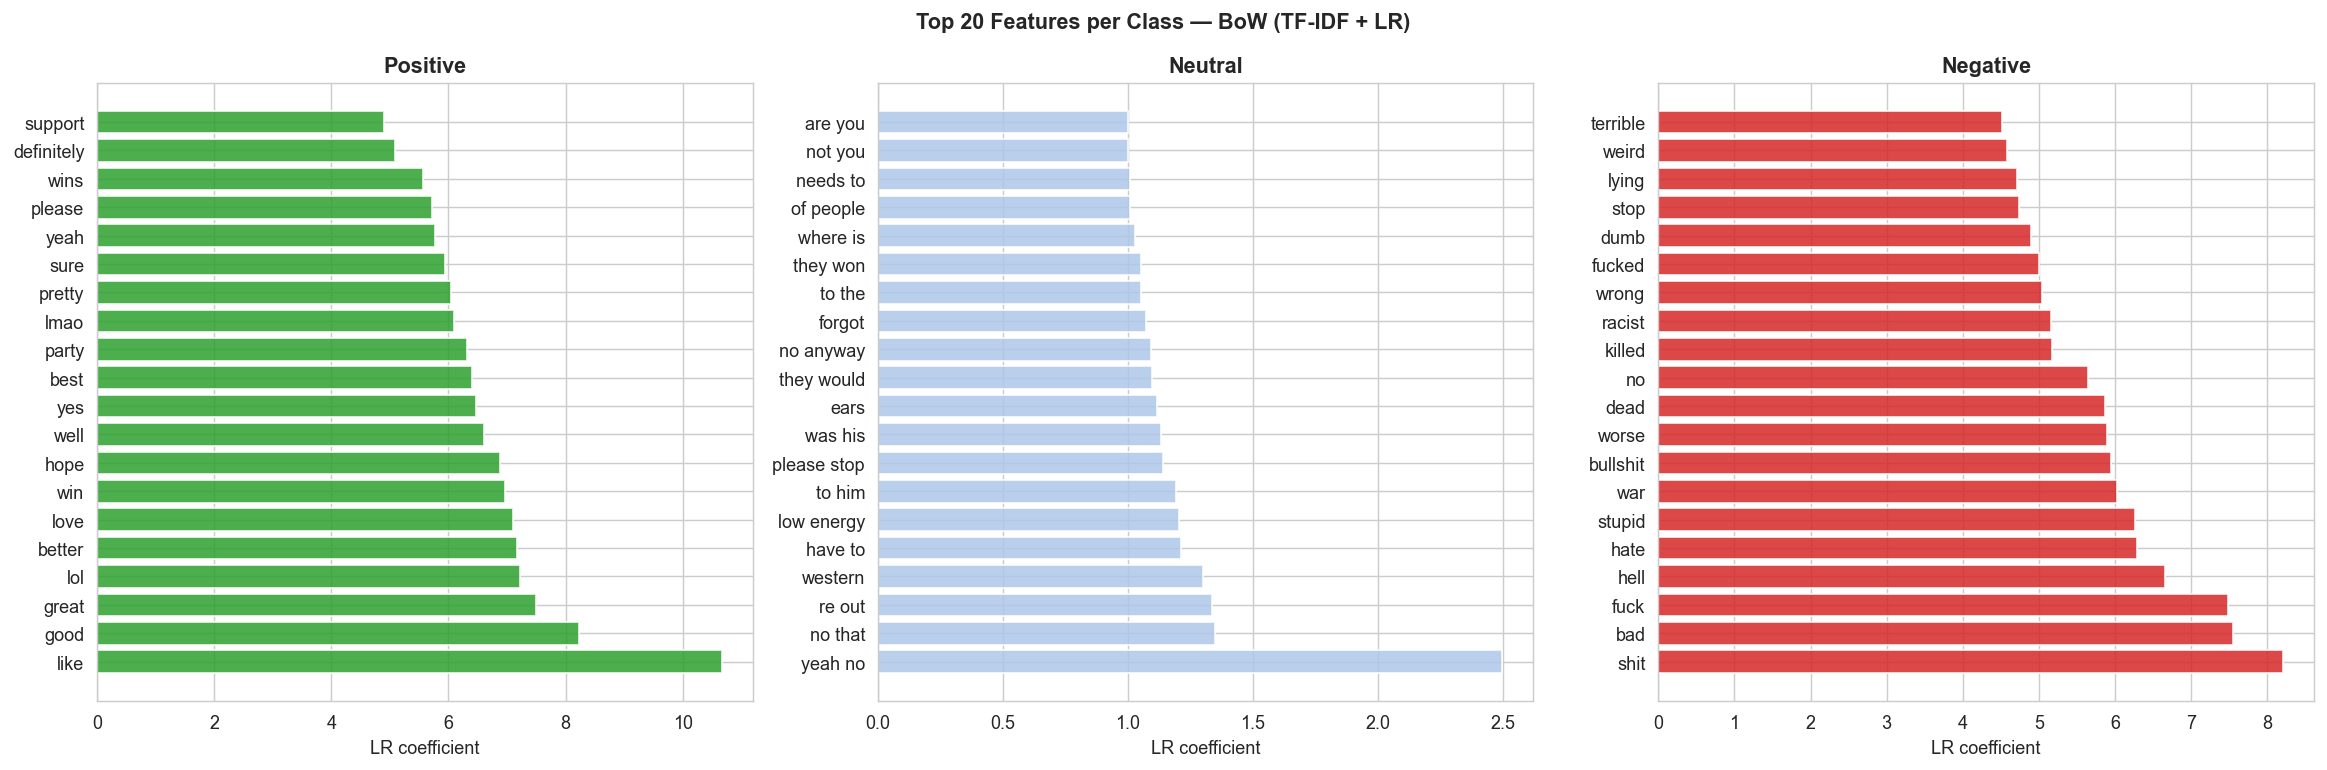

In [79]:
feature_names = np.array(tfidf.get_feature_names_out())
TOP_N = 20

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Top 20 Features per Class — BoW (TF-IDF + LR)', fontweight='bold')
for ax, label in zip(axes, LABEL_ORDER):
    idx = list(lr.classes_).index(label)   # ← use lr.classes_, not LABEL_ORDER
    coefs = lr.coef_[idx]
    top   = np.argsort(coefs)[-TOP_N:][::-1]
    ax.barh(feature_names[top][::-1], coefs[top][::-1],
            color=LABEL_COLORS[label], alpha=0.85)
    ax.set_title(f'{label.capitalize()}', fontsize=12, fontweight='bold')
    ax.set_xlabel('LR coefficient')
    ax.invert_yaxis()
plt.tight_layout(); plt.show()

### 4.4 Temporal Predictions — BoW Over Time
Apply BoW to a 200k stratified sample of all comments to build a daily sentiment trend.
Saves to `bow_temporal.parquet` — also used as the pool for the 12k candidate basis (Section 5).

✓ BoW temporal loaded: 197,524 rows


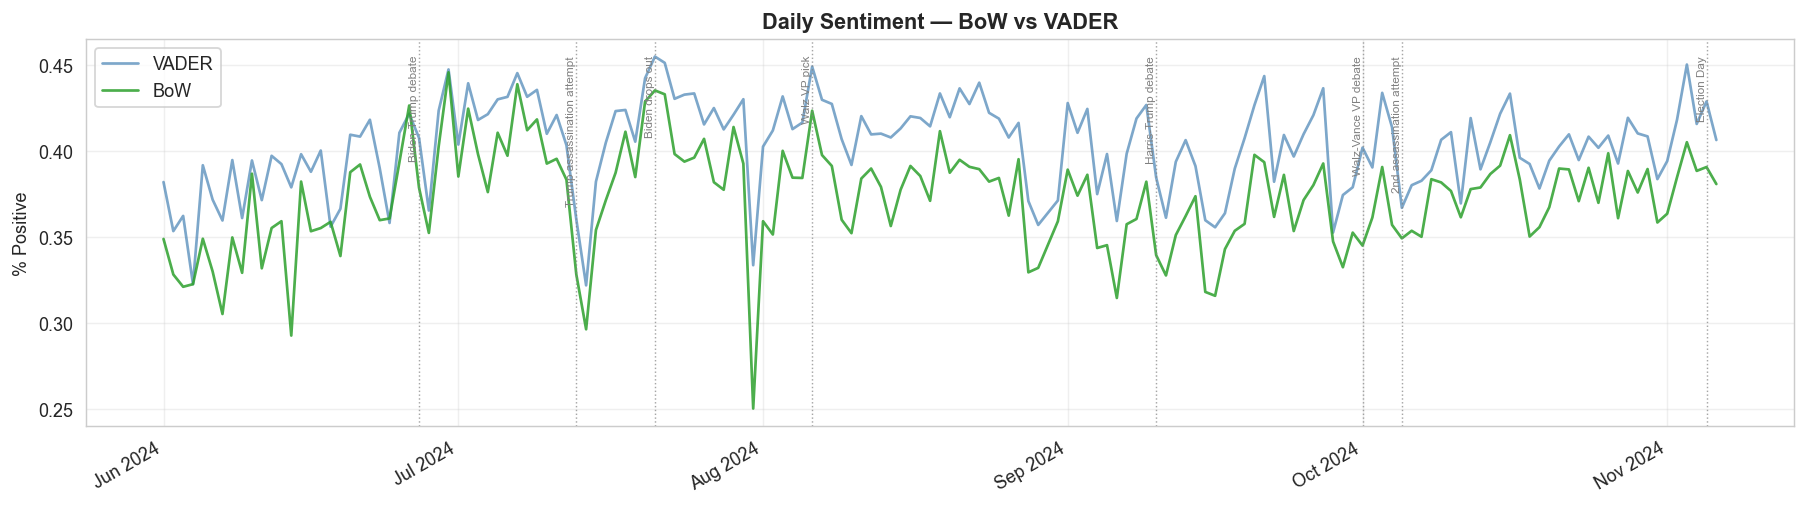

In [68]:
_BOW_TEMP = RESULTS_DIR / 'bow_temporal.parquet'

if _BOW_TEMP.exists():
    df_temporal = pd.read_parquet(_BOW_TEMP)
    df_temporal['date_day'] = pd.to_datetime(df_temporal['date_day'])
    print(f'✓ BoW temporal loaded: {len(df_temporal):,} rows')
else:
    print('Building BoW temporal predictions (200k sample)...')
    BOW_TEMPORAL_N = 200_000
    df_temporal = (
        df.groupby('month', group_keys=False)
        .apply(lambda g: g.sample(
            min(len(g), int(BOW_TEMPORAL_N * len(g) / len(df))),
            random_state=RANDOM_STATE + 1
        ))
    ).copy()
    df_temporal['text_clean'] = df_temporal['body'].apply(clean_text)
    df_temporal = df_temporal[df_temporal['text_clean'].str.strip().str.len() > 5]
    X_temp = tfidf.transform(df_temporal['text_clean'].values)
    df_temporal['bow_label'] = lr.predict(X_temp)
    df_temporal['mentions_trump'] = df_temporal['body'].str.contains(
        r'\b(trump|donald|maga|republican|gop)\b', case=False, regex=True, na=False)
    df_temporal['mentions_harris_biden'] = df_temporal['body'].str.contains(
        r'\b(harris|kamala|biden|democrat|walz)\b', case=False, regex=True, na=False)
    df_temporal.drop(columns=['text_clean'], errors='ignore').to_parquet(_BOW_TEMP, index=False)
    print(f'✓ BoW temporal saved → {_BOW_TEMP}  ({len(df_temporal):,} rows)')

# Daily positive rate
daily_bow = df_temporal.groupby('date_day')['bow_label'].apply(
    lambda x: (x == 'positive').mean()
).rename('bow_pos')
daily_vader = df_temporal.groupby('date_day')['vader_label'].apply(
    lambda x: (x == 'positive').mean()
).rename('vader_pos')

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily_vader.index, daily_vader.values, label='VADER', color='steelblue', lw=1.5, alpha=0.7)
ax.plot(daily_bow.index,   daily_bow.values,   label='BoW',   color='#2ca02c',  lw=1.5, alpha=0.85)
for d_str, label in EVENTS.items():
    d = pd.to_datetime(d_str)
    ax.axvline(d, color='gray', lw=0.8, ls=':', alpha=0.7)
    ax.text(d, ax.get_ylim()[1]*0.98, label, rotation=90,
            va='top', ha='right', fontsize=6.5, color='gray')
ax.set_ylabel('% Positive'); ax.set_title('Daily Sentiment — BoW vs VADER', fontweight='bold')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.legend(); ax.grid(True, alpha=0.3)
plt.gcf().autofmt_xdate(); plt.tight_layout(); plt.show()

## 5. Build 12k Candidate Basis

Filter `bow_temporal` for comments mentioning Trump or Harris, then sample **2,000/month**
across 6 months → 12,000 comments. BoW labels are inherited directly from `bow_temporal`.
RoBERTa and GPT are run on this same set in Sections 6 & 7.

**Checkpoint:** `candidate_basis_all_labels.parquet`  
If it exists with all four label columns, everything from Section 5 onwards loads instantly.

In [69]:
_BASIS_PATH = RESULTS_DIR / 'candidate_basis_all_labels.parquet'
BASIS_PER_MONTH = 2_000

def _basis_ready(path):
    if not path.exists(): return False
    cols = pd.read_parquet(path).columns.tolist()
    return all(c in cols for c in ['vader_label','bow_label','rob_label','gpt_label'])

if _basis_ready(_BASIS_PATH):
    df_basis = pd.read_parquet(_BASIS_PATH)
    df_basis['date_day'] = pd.to_datetime(df_basis['date_day'])
    print(f'✓ Full basis loaded: {len(df_basis):,} comments (all 4 labels present)')
    print(f'  Columns: {df_basis.columns.tolist()}')
    for col in ['vader_label','bow_label','rob_label','gpt_label']:
        vc   = df_basis[col].value_counts()
        dist = '  '.join(f'{l}: {vc.get(l,0):,} ({vc.get(l,0)/len(df_basis)*100:.1f}%)'
                         for l in LABEL_ORDER)
        print(f'  {col:12s}: {dist}')
else:
    print('Building 12k candidate basis from bow_temporal...')
    cand = df_temporal[
        df_temporal['mentions_trump'] | df_temporal['mentions_harris_biden']
    ].copy()
    print(f'  Candidate pool: {len(cand):,} comments')
    for m in MONTHS_ORDER:
        print(f'    {m}: {(cand["month"]==m).sum():,} comments available')
    df_basis = (
        cand.groupby('month', group_keys=False)
        .apply(lambda g: g.sample(min(len(g), BASIS_PER_MONTH), random_state=RANDOM_STATE))
    ).copy().reset_index(drop=True)
    print(f'\n✓ Basis sampled: {len(df_basis):,} comments')
    print(f'  Per month: {df_basis["month"].value_counts()[MONTHS_ORDER].to_dict()}')
    # Save with bow_label already present; rob_label + gpt_label added in §6 & §7
    df_basis.to_parquet(_BASIS_PATH, index=False)
    print(f'  Saved (BoW labels) → {_BASIS_PATH}')

✓ Full basis loaded: 12,000 comments (all 4 labels present)
  Columns: ['comment_id', 'post_id', 'body', 'date', 'date_day', 'month', 'mentions_trump', 'mentions_harris_biden', 'vader_label', 'bow_label', 'rob_label', 'gpt_label']
  vader_label : positive: 5,437 (45.3%)  neutral: 1,647 (13.7%)  negative: 4,916 (41.0%)
  bow_label   : positive: 5,174 (43.1%)  neutral: 2,075 (17.3%)  negative: 4,751 (39.6%)
  rob_label   : positive: 886 (7.4%)  neutral: 3,524 (29.4%)  negative: 7,590 (63.2%)
  gpt_label   : positive: 2,286 (19.1%)  neutral: 1,296 (10.8%)  negative: 8,418 (70.2%)


## 6. Approach 2 — RoBERTa

**Model:** `cardiffnlp/twitter-roberta-base-sentiment-latest`

Two inference passes — both checkpointed:
- **6.2** — 12k candidate basis → adds `rob_label` to `df_basis`
- **6.3** — 50k temporal sample → `rob_temporal.parquet` (daily trend line)

The model is only downloaded if at least one checkpoint is missing.

### 6.1 Load Model & Tokenizer

In [70]:
import torch
from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification
from tqdm.auto import tqdm

_ROB_TEMP_PATH = RESULTS_DIR / 'rob_temporal.parquet'
_basis_has_rob = 'rob_label' in df_basis.columns
_temp_exists   = _ROB_TEMP_PATH.exists()

LABEL_MAP  = {'positive': 'positive', 'neutral': 'neutral', 'negative': 'negative'}
MODEL_NAME = 'cardiffnlp/twitter-roberta-base-sentiment-latest'

if _basis_has_rob and _temp_exists:
    roberta_pipe = None
    print('✓ Both RoBERTa checkpoints found — skipping model download')
    print(f'  Basis rob_label  : present ({df_basis["rob_label"].value_counts().to_dict()})')
    print(f'  rob_temporal.parquet: {_ROB_TEMP_PATH}')
else:
    device = 0 if torch.cuda.is_available() else -1
    print(f'Loading RoBERTa on: {"GPU" if device == 0 else "CPU"}')
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model     = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
    roberta_pipe = pipeline(
        'sentiment-analysis',
        model=model, tokenizer=tokenizer,
        device=device, truncation=True, max_length=128, batch_size=64,
    )
    print(f'✓ Model loaded: {MODEL_NAME}')

✓ Both RoBERTa checkpoints found — skipping model download
  Basis rob_label  : present ({'negative': 7590, 'neutral': 3524, 'positive': 886})
  rob_temporal.parquet: C:\Users\Dell\Desktop\NLP\Final project\Datasources\model_results\rob_temporal.parquet


### 6.2 RoBERTa Inference on 12k Basis
Adds `rob_label` (and `rob_score`) to `df_basis`. Skipped if already present.

In [71]:
if 'rob_label' in df_basis.columns:
    print(f'✓ rob_label already in basis — skipping inference')
    print(f'  Distribution: {df_basis["rob_label"].value_counts().to_dict()}')
else:
    print(f'Running RoBERTa on {len(df_basis):,} basis comments...')
    texts = df_basis['body'].apply(clean_text_roberta).tolist()
    results = []
    for out in tqdm(roberta_pipe(texts, batch_size=64),
                    total=len(texts), desc='RoBERTa basis'):
        results.append(out)
    df_basis['rob_label'] = [LABEL_MAP[r['label']] for r in results]
    df_basis['rob_score'] = [r['score']             for r in results]
    df_basis.to_parquet(_BASIS_PATH, index=False)
    print(f'✓ rob_label added and basis saved → {_BASIS_PATH}')
    print(f'  Distribution: {df_basis["rob_label"].value_counts().to_dict()}')

✓ rob_label already in basis — skipping inference
  Distribution: {'negative': 7590, 'neutral': 3524, 'positive': 886}


### 6.3 RoBERTa Temporal Predictions — 50k Sample
Applies RoBERTa to a stratified 50k sample for a smooth **daily** sentiment trend line.
Saves to `rob_temporal.parquet`. Skipped if checkpoint exists.

✓ RoBERTa temporal loaded: 49,514 rows


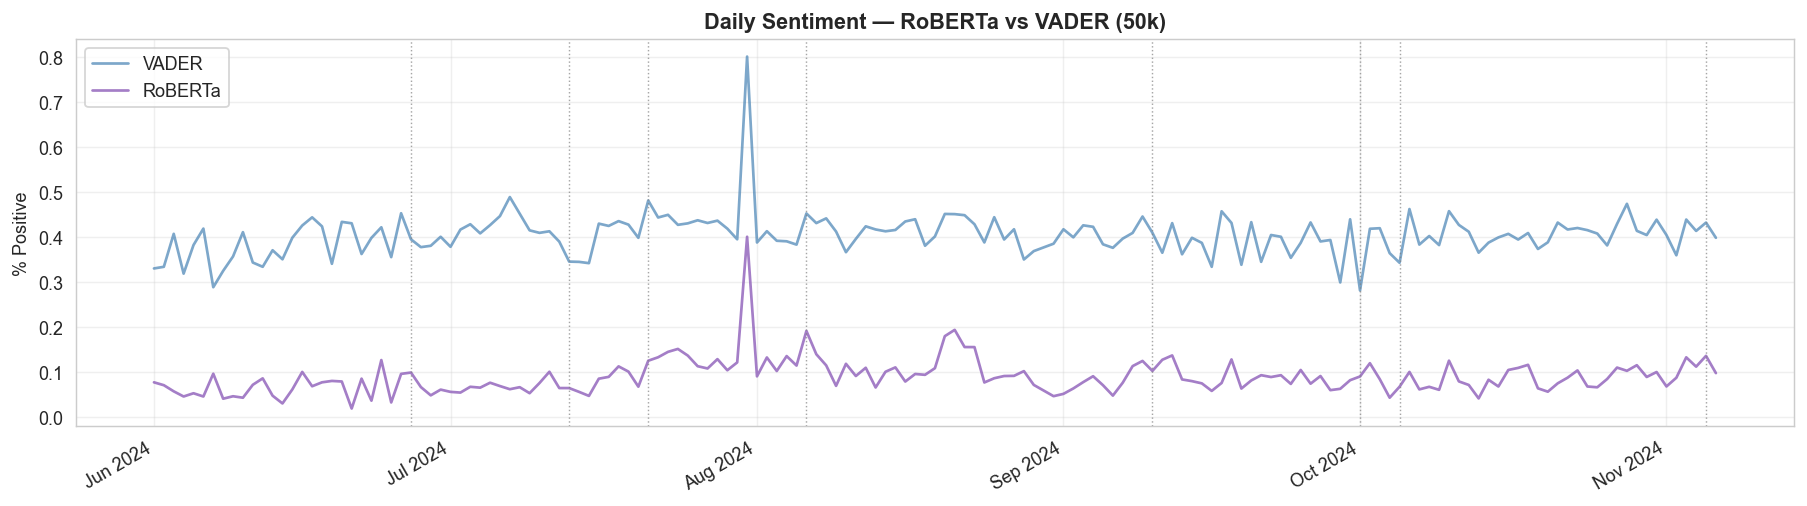

In [72]:
if _ROB_TEMP_PATH.exists():
    df_rob_temp = pd.read_parquet(_ROB_TEMP_PATH)
    df_rob_temp['date_day'] = pd.to_datetime(df_rob_temp['date_day'])
    print(f'✓ RoBERTa temporal loaded: {len(df_rob_temp):,} rows')
else:
    print('Running RoBERTa temporal inference (50k sample)...')
    ROB_TEMPORAL_N = 50_000
    df_rob_temp = (
        df.groupby('month', group_keys=False)
        .apply(lambda g: g.sample(
            min(len(g), int(ROB_TEMPORAL_N * len(g) / len(df))),
            random_state=RANDOM_STATE + 2
        ))
    ).copy()
    df_rob_temp['text_rob'] = df_rob_temp['body'].apply(clean_text_roberta)
    df_rob_temp = df_rob_temp[df_rob_temp['text_rob'].str.strip().str.len() > 5].reset_index(drop=True)
    results_temp = []
    for out in tqdm(roberta_pipe(df_rob_temp['text_rob'].tolist(), batch_size=64),
                    total=len(df_rob_temp), desc='RoBERTa temporal'):
        results_temp.append(out)
    df_rob_temp['rob_label'] = [LABEL_MAP[r['label']] for r in results_temp]
    df_rob_temp['mentions_trump'] = df_rob_temp['body'].str.contains(
        r'\b(trump|donald|maga|republican|gop)\b', case=False, regex=True, na=False)
    df_rob_temp['mentions_harris_biden'] = df_rob_temp['body'].str.contains(
        r'\b(harris|kamala|biden|democrat|walz)\b', case=False, regex=True, na=False)
    df_rob_temp.drop(columns=['text_rob'], errors='ignore').to_parquet(_ROB_TEMP_PATH, index=False)
    print(f'✓ RoBERTa temporal saved → {_ROB_TEMP_PATH}  ({len(df_rob_temp):,} rows)')

# Daily trend chart
daily_rob = df_rob_temp.groupby('date_day')['rob_label'].apply(
    lambda x: (x == 'positive').mean()
).rename('rob_pos')
daily_vader_t = df_rob_temp.groupby('date_day')['vader_label'].apply(
    lambda x: (x == 'positive').mean()
).rename('vader_pos')

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily_vader_t.index, daily_vader_t.values, label='VADER',   color='steelblue', lw=1.5, alpha=0.7)
ax.plot(daily_rob.index,     daily_rob.values,     label='RoBERTa', color='#9467bd',   lw=1.5, alpha=0.85)
for d_str in EVENTS:
    d = pd.to_datetime(d_str)
    ax.axvline(d, color='gray', lw=0.8, ls=':', alpha=0.7)
ax.set_ylabel('% Positive'); ax.set_title('Daily Sentiment — RoBERTa vs VADER (50k)', fontweight='bold')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.legend(); ax.grid(True, alpha=0.3)
plt.gcf().autofmt_xdate(); plt.tight_layout(); plt.show()

## 7. Approach 3 — GPT-4o-mini

**Model:** `gpt-4o-mini` via OpenAI API with 6-shot prompting.

Runs directly on the **12k candidate basis** — no separate eval set needed.
Checkpoints every 500 rows so inference can be interrupted and resumed.

### 7.1 API Setup & Classify Function

In [73]:
import os
from openai import OpenAI

client = OpenAI(api_key=os.environ['OPENAI_API_KEY'])  # never hardcode the key

SYSTEM_PROMPT = """You are a political sentiment classifier.
Given a Reddit comment from r/politics during the 2024 US Presidential Election,
classify the overall sentiment as expressed by the author.
Respond with exactly one word — no punctuation, no explanation:
  positive  → the author expresses approval, hope, excitement, or support
  neutral   → the author states facts, asks questions, or shows no clear sentiment
  negative  → the author expresses disapproval, fear, anger, frustration, or criticism

Examples:
Comment: "Harris gave a really strong debate performance tonight."
Label: positive
Comment: "The jury returned a guilty verdict on all 34 counts."
Label: neutral
Comment: "This is an absolute disaster. I can't believe we let it get this far."
Label: negative
Comment: "The latest Quinnipiac poll shows the race within the margin of error."
Label: neutral
Comment: "Seeing record early voting numbers is genuinely encouraging."
Label: positive
Comment: "His economic policies have been completely destructive for working-class families."
Label: negative"""

def classify_comment(text: str, retries: int = 3, delay: float = 2.0) -> str:
    for attempt in range(retries):
        try:
            response = client.chat.completions.create(
                model='gpt-4o-mini',
                messages=[
                    {'role': 'system', 'content': SYSTEM_PROMPT},
                    {'role': 'user',   'content': f'Comment: {text[:1000]}'},
                ],
                max_tokens=10, temperature=0,
            )
            label = response.choices[0].message.content.strip().lower()
            for candidate in ('positive', 'neutral', 'negative'):
                if candidate in label:
                    return candidate
            return 'neutral'
        except Exception as e:
            if attempt < retries - 1:
                time.sleep(delay * (2 ** attempt))
            else:
                return 'neutral'

print('GPT client and classify_comment defined.')

GPT client and classify_comment defined.


### 7.2 GPT Inference on 12k Basis
Checkpoints every 500 rows — safe to interrupt and rerun.
Skipped entirely if `gpt_label` already present in `df_basis`.

In [75]:
if 'gpt_label' in df_basis.columns:
    print(f'✓ gpt_label already in basis — skipping inference')
    print(f'  Distribution: {df_basis["gpt_label"].value_counts().to_dict()}')
else:
    print(f'Running GPT-4o-mini on {len(df_basis):,} basis comments...')
    print('  Checkpointing every 500 rows — safe to interrupt and resume.')
    CHECKPOINT_EVERY = 500
    gpt_labels = [''] * len(df_basis)

    # Resume from partial checkpoint if it exists
    _GPT_PARTIAL = RESULTS_DIR / 'basis_gpt_partial.parquet'
    start_idx = 0
    if _GPT_PARTIAL.exists():
        partial = pd.read_parquet(_GPT_PARTIAL)
        done    = partial['gpt_label'].notna() & (partial['gpt_label'] != '')
        n_done  = done.sum()
        gpt_labels[:n_done] = partial['gpt_label'][:n_done].tolist()
        start_idx = n_done
        print(f'  Resuming from row {start_idx:,}')

    for i in tqdm(range(start_idx, len(df_basis)), desc='GPT-4o-mini basis'):
        gpt_labels[i] = classify_comment(df_basis.iloc[i]['body'])
        time.sleep(0.1)
        if (i + 1) % CHECKPOINT_EVERY == 0:
            _partial_df = df_basis.copy()
            _partial_df['gpt_label'] = gpt_labels
            _partial_df.to_parquet(_GPT_PARTIAL, index=False)

    df_basis['gpt_label'] = gpt_labels
    print(f'\n✓ GPT inference complete')
    print(f'  Distribution: {df_basis["gpt_label"].value_counts().to_dict()}')

✓ gpt_label already in basis — skipping inference
  Distribution: {'negative': 8418, 'positive': 2286, 'neutral': 1296}


## 8. Save Combined Basis (All 4 Labels)
Write the final `candidate_basis_all_labels.parquet` with VADER + BoW + RoBERTa + GPT labels.
On subsequent runs, Section 5 loads this directly and skips all inference.

In [76]:
required_cols = ['vader_label', 'bow_label', 'rob_label', 'gpt_label']
missing = [c for c in required_cols if c not in df_basis.columns]
if missing:
    print(f'⚠  Missing columns: {missing} — run the relevant sections above first.')
else:
    df_basis.to_parquet(_BASIS_PATH, index=False)
    print(f'✓ Combined basis saved → {_BASIS_PATH}')
    print(f'  Shape   : {df_basis.shape}')
    print(f'  Columns : {df_basis.columns.tolist()}')
    print()
    for col in required_cols:
        vc   = df_basis[col].value_counts()
        dist = '  '.join(f'{l}: {vc.get(l,0):,} ({vc.get(l,0)/len(df_basis)*100:.1f}%)'
                         for l in LABEL_ORDER)
        print(f'  {col:12s}: {dist}')
    # Clean up partial GPT checkpoint if present
    _GPT_PARTIAL = RESULTS_DIR / 'basis_gpt_partial.parquet'
    if _GPT_PARTIAL.exists():
        _GPT_PARTIAL.unlink()
        print('  Cleaned up partial GPT checkpoint.')

✓ Combined basis saved → C:\Users\Dell\Desktop\NLP\Final project\Datasources\model_results\candidate_basis_all_labels.parquet
  Shape   : (12000, 12)
  Columns : ['comment_id', 'post_id', 'body', 'date', 'date_day', 'month', 'mentions_trump', 'mentions_harris_biden', 'vader_label', 'bow_label', 'rob_label', 'gpt_label']

  vader_label : positive: 5,437 (45.3%)  neutral: 1,647 (13.7%)  negative: 4,916 (41.0%)
  bow_label   : positive: 5,174 (43.1%)  neutral: 2,075 (17.3%)  negative: 4,751 (39.6%)
  rob_label   : positive: 886 (7.4%)  neutral: 3,524 (29.4%)  negative: 7,590 (63.2%)
  gpt_label   : positive: 2,286 (19.1%)  neutral: 1,296 (10.8%)  negative: 8,418 (70.2%)


## 9. Overall Metrics
Accuracy, Macro F1, Weighted F1 for each model vs VADER on the 12k basis.

  OVERALL METRICS — 12k candidate basis  (VADER = ground truth)
  Model                    Accuracy   Macro F1  Weighted F1
  ----------------------------------------------------------
  BoW (TF-IDF+LR)            0.7784     0.7612       0.7801
  RoBERTa                    0.4775     0.4087       0.4240
  GPT-4o-mini                0.4937     0.4245       0.4580


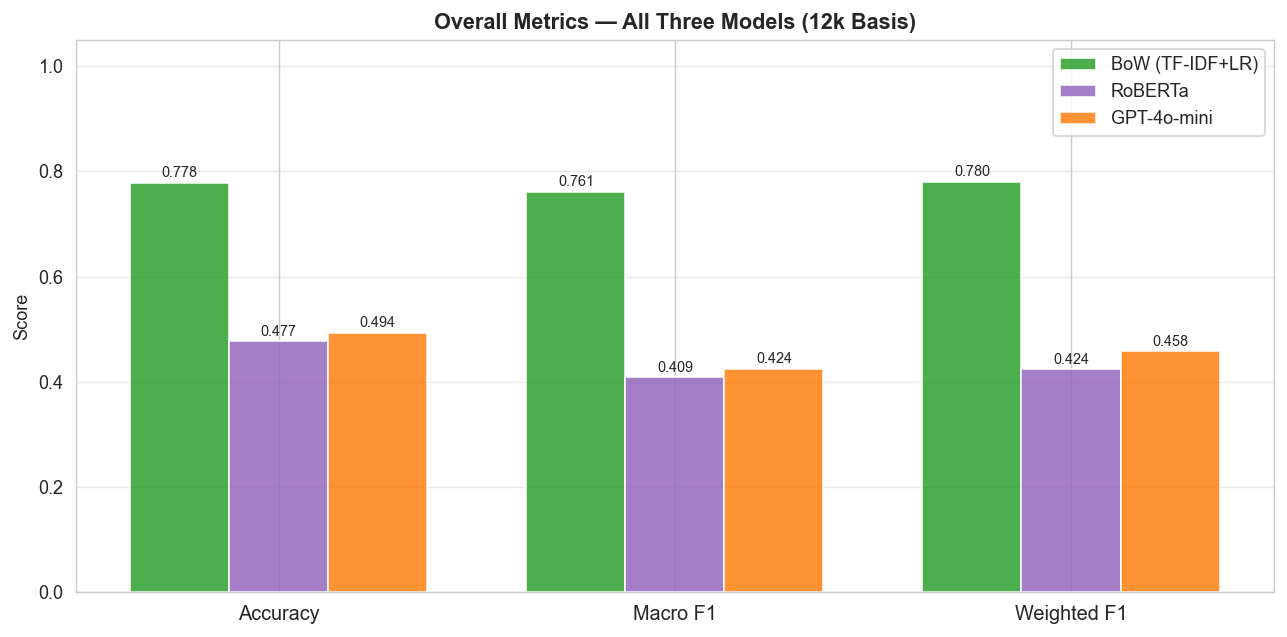

In [77]:
y_true = df_basis['vader_label'].values
comp   = {}
print('=' * 72)
print('  OVERALL METRICS — 12k candidate basis  (VADER = ground truth)')
print('=' * 72)
print(f'  {"Model":<22} {"Accuracy":>10} {"Macro F1":>10} {"Weighted F1":>12}')
print('  ' + '-' * 58)
for col, name in zip(MODELS, MODEL_NAMES):
    if col not in df_basis.columns: continue
    yp  = df_basis[col].values
    acc = accuracy_score(y_true, yp)
    fm  = f1_score(y_true, yp, average='macro',    labels=LABEL_ORDER)
    fw  = f1_score(y_true, yp, average='weighted', labels=LABEL_ORDER)
    comp[col] = {'name': name, 'acc': acc, 'f1_mac': fm, 'f1_wei': fw}
    print(f'  {name:<22} {acc:>10.4f} {fm:>10.4f} {fw:>12.4f}')
print('=' * 72)

fig, ax = plt.subplots(figsize=(10, 5))
metrics = ['acc', 'f1_mac', 'f1_wei']
mlabels = ['Accuracy', 'Macro F1', 'Weighted F1']
x = np.arange(len(mlabels)); w = 0.25
for i, (col, name, color) in enumerate(zip(MODELS, MODEL_NAMES, MODEL_COLORS)):
    if col not in comp: continue
    vals = [comp[col][m] for m in metrics]
    bars = ax.bar(x + i*w, vals, w, label=name, color=color, alpha=0.85)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8)
ax.set_xticks(x+w); ax.set_xticklabels(mlabels, fontsize=11)
ax.set_ylim(0, 1.05); ax.set_ylabel('Score')
ax.set_title('Overall Metrics — All Three Models (12k Basis)', fontweight='bold')
ax.legend(); ax.grid(axis='y', alpha=0.4)
plt.tight_layout(); plt.show()

## 10. Per-Class Breakdown
Precision, Recall, F1 per sentiment class for each model.


── BoW (TF-IDF+LR) ──
              precision    recall  f1-score   support

    positive     0.8233    0.7835    0.8029      5437
     neutral     0.6265    0.7893    0.6985      1647
    negative     0.7958    0.7691    0.7822      4916

    accuracy                         0.7784     12000
   macro avg     0.7486    0.7807    0.7612     12000
weighted avg     0.7851    0.7784    0.7801     12000


── RoBERTa ──
              precision    recall  f1-score   support

    positive     0.8567    0.1396    0.2401      5437
     neutral     0.2389    0.5112    0.3257      1647
    negative     0.5440    0.8399    0.6603      4916

    accuracy                         0.4775     12000
   macro avg     0.5465    0.4969    0.4087     12000
weighted avg     0.6438    0.4775    0.4240     12000


── GPT-4o-mini ──
              precision    recall  f1-score   support

    positive     0.6286    0.2643    0.3721      5437
     neutral     0.3326    0.2617    0.2929      1647
    negative     0

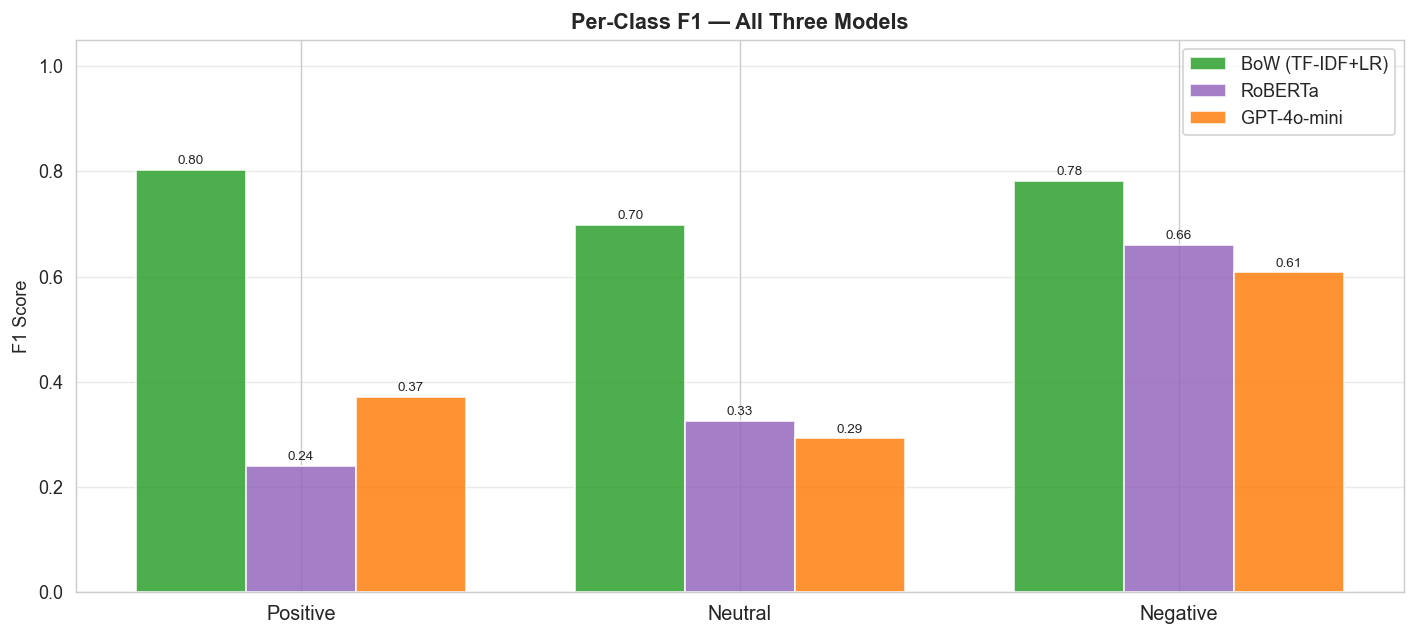

In [78]:
for col, name in zip(MODELS, MODEL_NAMES):
    if col not in df_basis.columns: continue
    print(f'\n── {name} ──')
    print(classification_report(y_true, df_basis[col].values, labels=LABEL_ORDER, digits=4))

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(LABEL_ORDER)); w = 0.25
for i, (col, name, color) in enumerate(zip(MODELS, MODEL_NAMES, MODEL_COLORS)):
    if col not in df_basis.columns: continue
    rep = classification_report(y_true, df_basis[col].values,
                                labels=LABEL_ORDER, output_dict=True)
    f1s  = [rep[l]['f1-score'] for l in LABEL_ORDER]
    bars = ax.bar(x + i*w, f1s, w, label=name, color=color, alpha=0.85)
    for bar, val in zip(bars, f1s):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                f'{val:.2f}', ha='center', va='bottom', fontsize=7.5)
ax.set_xticks(x+w); ax.set_xticklabels([l.capitalize() for l in LABEL_ORDER], fontsize=11)
ax.set_ylim(0, 1.05); ax.set_ylabel('F1 Score')
ax.set_title('Per-Class F1 — All Three Models', fontweight='bold')
ax.legend(); ax.grid(axis='y', alpha=0.4)
plt.tight_layout(); plt.show()

## 11. Confusion Matrices
Row = VADER (true), Column = model prediction.

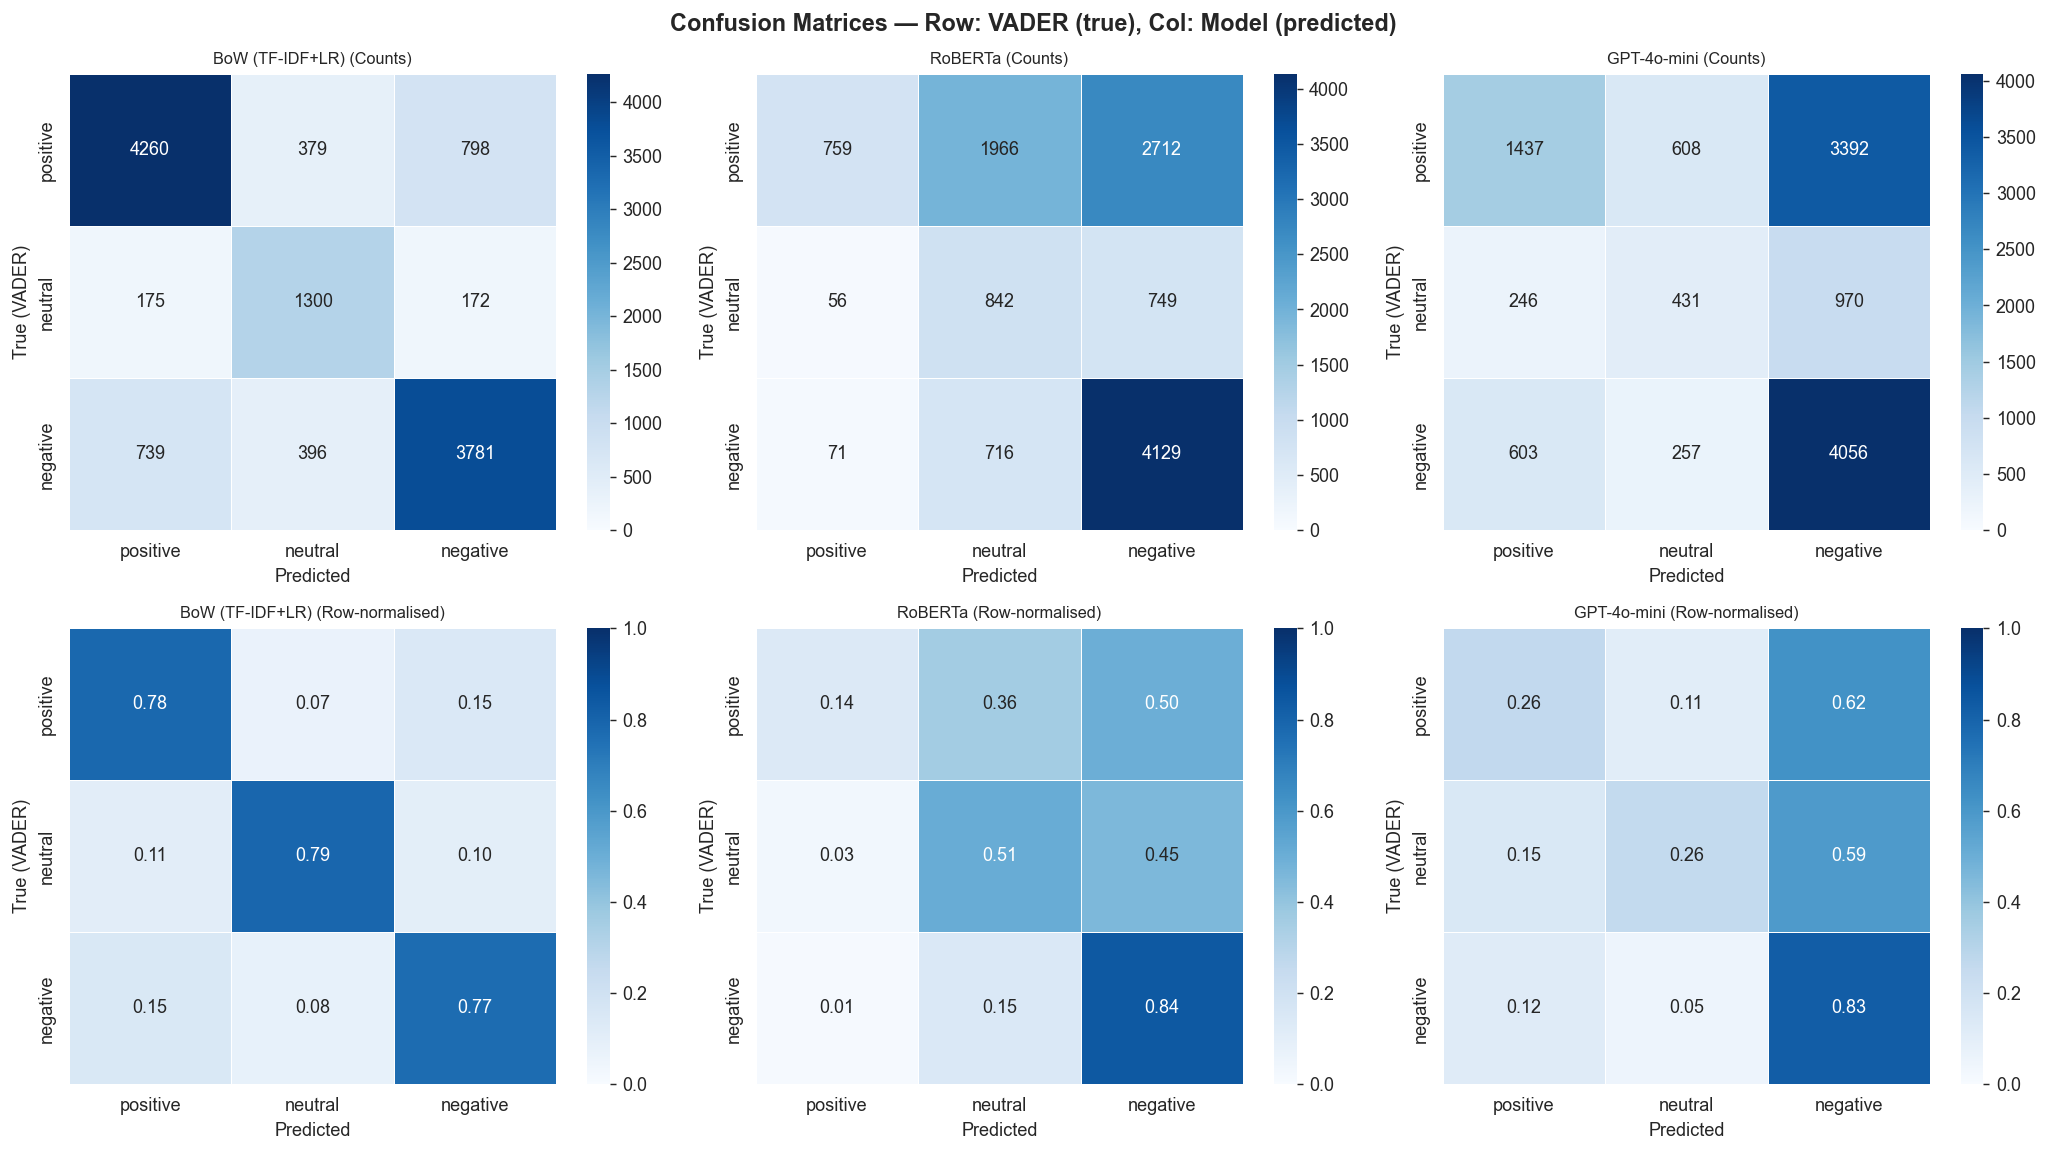

In [80]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Confusion Matrices — Row: VADER (true), Col: Model (predicted)',
             fontsize=13, fontweight='bold')
for i, (col, name) in enumerate(zip(MODELS, MODEL_NAMES)):
    if col not in df_basis.columns: continue
    cm      = confusion_matrix(y_true, df_basis[col].values, labels=LABEL_ORDER)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    for j, (mat, suffix, fmt) in enumerate([
        (cm,      'Counts',         'd'),
        (cm_norm, 'Row-normalised', '.2f'),
    ]):
        ax = axes[j][i]
        sns.heatmap(mat, annot=True, fmt=fmt, ax=ax,
                    xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER,
                    cmap='Blues', linewidths=0.5, vmin=0, vmax=None if fmt=='d' else 1)
        ax.set_title(f'{name} ({suffix})', fontsize=9)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True (VADER)')
plt.tight_layout(); plt.show()

## 12. Pairwise Agreement & Cohen's Kappa

  Pair                    Agreement   Cohen Kappa
  ------------------------------------------------
  BoW vs RoBERTa              0.478        0.2175
  BoW vs GPT                  0.490        0.1801
  RoBERTa vs GPT              0.683        0.3800

  All 3 agree: 0.378


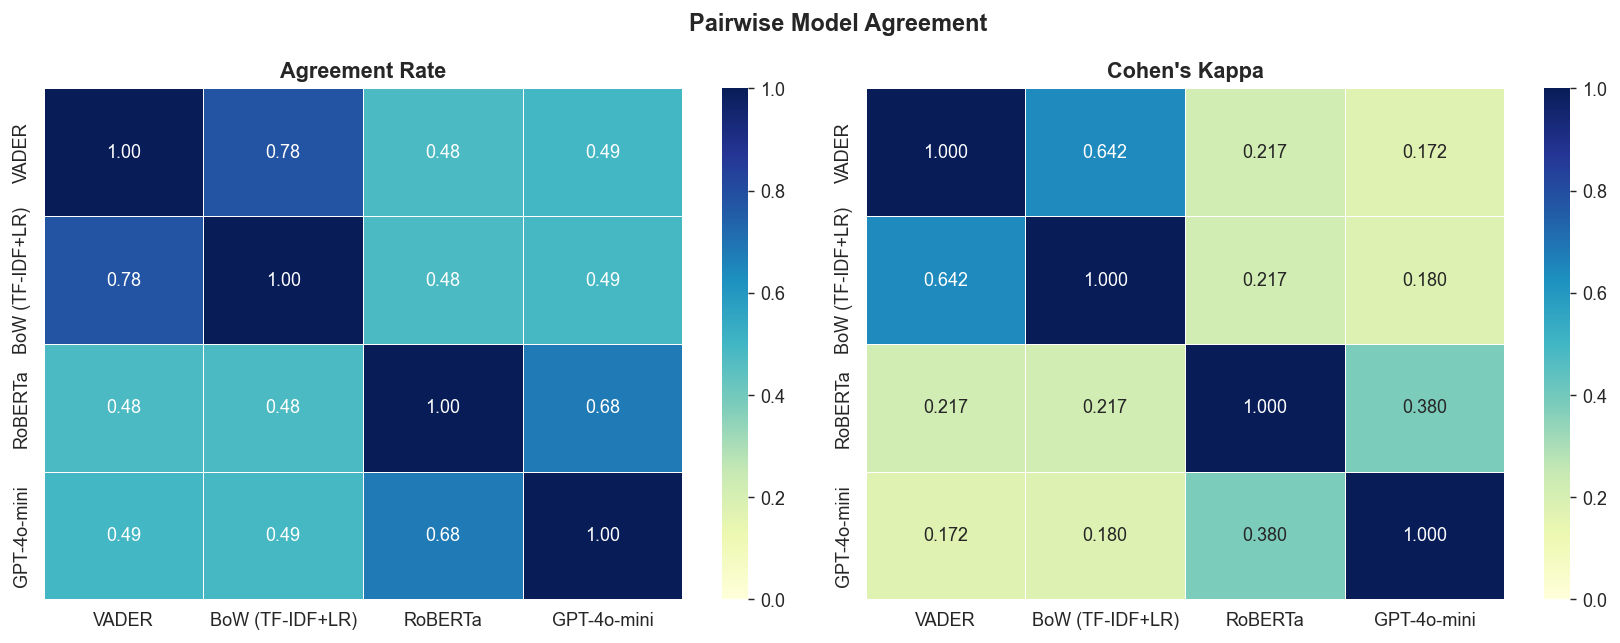

In [81]:
pairs = [
    ('bow_label', 'rob_label', 'BoW vs RoBERTa'),
    ('bow_label', 'gpt_label', 'BoW vs GPT'),
    ('rob_label', 'gpt_label', 'RoBERTa vs GPT'),
]
print(f'  {"Pair":<22} {"Agreement":>10} {"Cohen Kappa":>13}')
print('  ' + '-' * 48)
for c1, c2, label in pairs:
    if c1 not in df_basis.columns or c2 not in df_basis.columns: continue
    agree = (df_basis[c1] == df_basis[c2]).mean()
    kappa = cohen_kappa_score(df_basis[c1], df_basis[c2])
    print(f'  {label:<22} {agree:>10.3f} {kappa:>13.4f}')
all_agree = (
    (df_basis['bow_label'] == df_basis['rob_label']) &
    (df_basis['bow_label'] == df_basis['gpt_label'])
).mean()
print(f'\n  All 3 agree: {all_agree:.3f}')

all_cols  = ['vader_label'] + MODELS
all_names = ['VADER'] + MODEL_NAMES
agree_mat = np.zeros((4,4)); kappa_mat = np.zeros((4,4))
for i, c1 in enumerate(all_cols):
    for j, c2 in enumerate(all_cols):
        if c1 not in df_basis.columns or c2 not in df_basis.columns: continue
        agree_mat[i,j] = (df_basis[c1] == df_basis[c2]).mean()
        kappa_mat[i,j] = cohen_kappa_score(df_basis[c1], df_basis[c2]) if i != j else 1.0
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, mat, title, fmt in [
    (axes[0], agree_mat, 'Agreement Rate', '.2f'),
    (axes[1], kappa_mat, "Cohen's Kappa",  '.3f'),
]:
    sns.heatmap(mat, annot=True, fmt=fmt, ax=ax,
                xticklabels=all_names, yticklabels=all_names,
                cmap='YlGnBu', vmin=0, vmax=1, linewidths=0.5)
    ax.set_title(title, fontweight='bold')
fig.suptitle('Pairwise Model Agreement', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

## 13. Temporal Breakdown
Monthly accuracy vs VADER — does performance drift across the campaign?

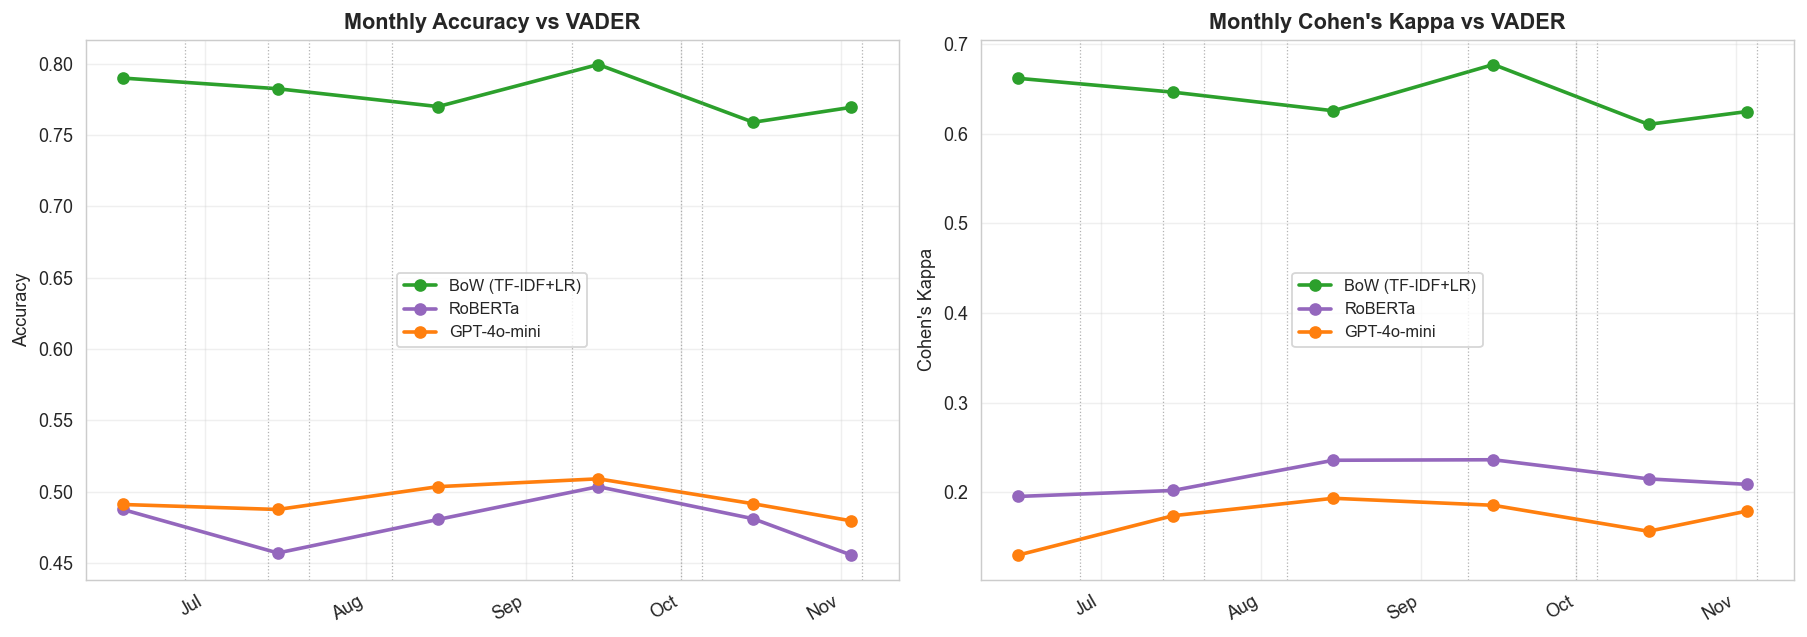

In [82]:
monthly_acc   = {n: [] for n in MODEL_NAMES}
monthly_kappa = {n: [] for n in MODEL_NAMES}
for month in MONTHS_ORDER:
    sub = df_basis[df_basis['month'] == month]
    yt  = sub['vader_label'].values
    for col, name in zip(MODELS, MODEL_NAMES):
        if col not in sub.columns: continue
        yp = sub[col].values
        monthly_acc[name].append(accuracy_score(yt, yp))
        monthly_kappa[name].append(cohen_kappa_score(yt, yp))
x_dates = pd.to_datetime([MONTH_MID[m] for m in MONTHS_ORDER])
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, data, ylabel, title in [
    (axes[0], monthly_acc,   'Accuracy',       'Monthly Accuracy vs VADER'),
    (axes[1], monthly_kappa, "Cohen's Kappa", "Monthly Cohen's Kappa vs VADER"),
]:
    for name, color in zip(MODEL_NAMES, MODEL_COLORS):
        ax.plot(x_dates, data[name], marker='o', lw=2, color=color, label=name)
    for d_str in EVENTS:
        d = pd.to_datetime(d_str)
        if pd.Timestamp('2024-06-01') <= d <= pd.Timestamp('2024-11-06'):
            ax.axvline(d, color='gray', lw=0.7, ls=':', alpha=0.6)
    ax.set_ylabel(ylabel); ax.set_title(title, fontweight='bold')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.gcf().autofmt_xdate(); plt.tight_layout(); plt.show()

## 14. Candidate Breakdown
Do models perform differently on Trump vs Harris comments?

  Subset          N     BoW (TF-IDF+LR)             RoBERTa         GPT-4o-mini
  ---------------------------------------------------------------------------
  Trump        8522              0.7799              0.4781              0.4894
  Harris       5743              0.7775              0.4651              0.5027
  Both         2265              0.7815              0.4481              0.5007


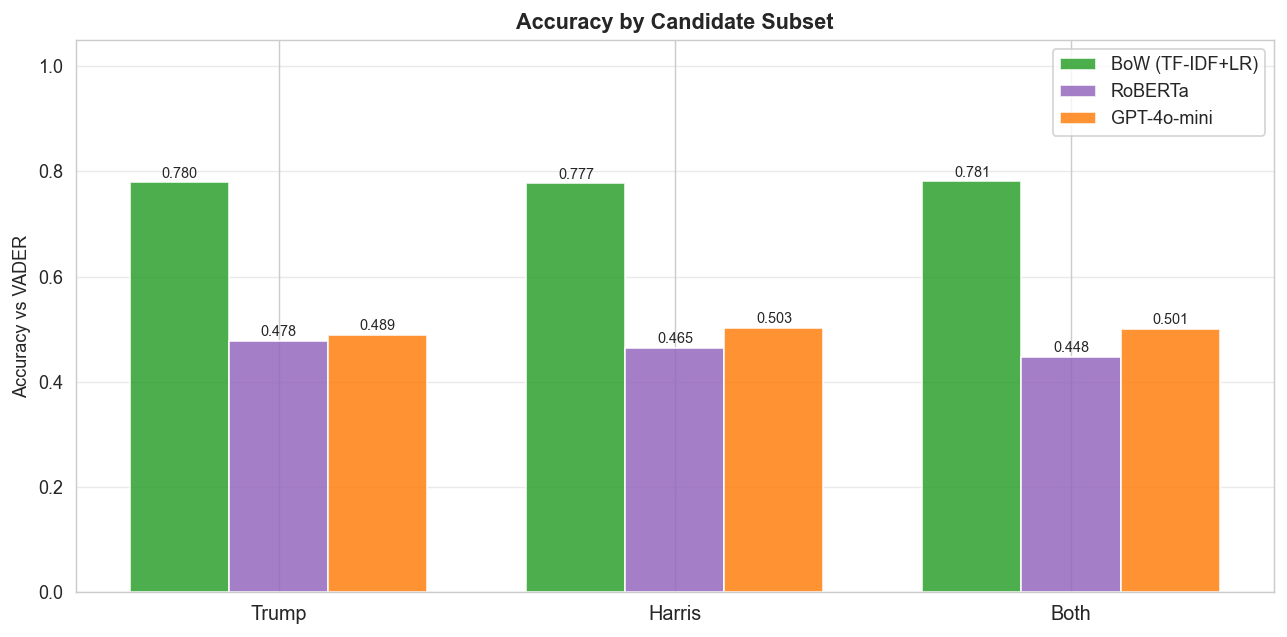

In [83]:
subsets = [
    (df_basis[df_basis['mentions_trump']],                                    'Trump'),
    (df_basis[df_basis['mentions_harris_biden']],                              'Harris'),
    (df_basis[df_basis['mentions_trump'] & df_basis['mentions_harris_biden']], 'Both'),
]
print(f'  {"Subset":<10} {"N":>6}  ' + '  '.join(f'{n:>18}' for n in MODEL_NAMES))
print('  ' + '-' * 75)
rows = []
for sub, label in subsets:
    yt   = sub['vader_label'].values
    accs = [accuracy_score(yt, sub[c].values) if c in sub.columns else None for c in MODELS]
    rows.append({'label': label, 'n': len(sub), **dict(zip(MODEL_NAMES, accs))})
    print(f'  {label:<10} {len(sub):>6}  ' +
          '  '.join(f'{a:>18.4f}' if a else f'{"N/A":>18}' for a in accs))
x = np.arange(len(subsets)); w = 0.25
fig, ax = plt.subplots(figsize=(10, 5))
for i, (name, color) in enumerate(zip(MODEL_NAMES, MODEL_COLORS)):
    vals = [r[name] for r in rows]
    bars = ax.bar(x + i*w, vals, w, label=name, color=color, alpha=0.85)
    for bar, val in zip(bars, vals):
        if val: ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.003,
                        f'{val:.3f}', ha='center', va='bottom', fontsize=8)
ax.set_xticks(x+w); ax.set_xticklabels([r['label'] for r in rows], fontsize=11)
ax.set_ylim(0, 1.05); ax.set_ylabel('Accuracy vs VADER')
ax.set_title('Accuracy by Candidate Subset', fontweight='bold')
ax.legend(); ax.grid(axis='y', alpha=0.4)
plt.tight_layout(); plt.show()

## 15. Error Analysis — 50 Examples Where Models Disagree

Comments where at least two models assign different labels, grouped by pattern:
all-3-differ, BoW outlier, RoBERTa outlier, GPT outlier, mixed two-way.
Each entry shows the raw comment, VADER silver label, and all three model labels.

In [84]:
import textwrap

LABEL_ICONS = {'positive': '🟢', 'neutral': '🟡', 'negative': '🔴'}
N_EXAMPLES  = 50
WRAP_WIDTH  = 100

bow = df_basis['bow_label']
rob = df_basis['rob_label']
gpt = df_basis['gpt_label']

mask_all3    = (bow != rob) & (bow != gpt) & (rob != gpt)
mask_bow_out = (bow != rob) & (bow != gpt) & (rob == gpt)
mask_rob_out = (rob != bow) & (rob != gpt) & (bow == gpt)
mask_gpt_out = (gpt != bow) & (gpt != rob) & (bow == rob)
mask_rest    = (
    ((bow != rob) | (bow != gpt) | (rob != gpt)) &
    ~mask_all3 & ~mask_bow_out & ~mask_rob_out & ~mask_gpt_out
)

groups = [
    ('All 3 Disagree',             df_basis[mask_all3],    8),
    ('BoW outlier  (RoBERTa=GPT)', df_basis[mask_bow_out], 12),
    ('RoBERTa outlier (BoW=GPT)',  df_basis[mask_rob_out], 12),
    ('GPT outlier  (BoW=RoBERTa)', df_basis[mask_gpt_out], 12),
    ('Mixed two-way',              df_basis[mask_rest],     6),
]

examples = []
for group_name, subset, n in groups:
    if len(subset) == 0: continue
    for _, row in subset.sample(min(n, len(subset)), random_state=42).iterrows():
        examples.append((group_name, row))

sep = '─' * 110
cur_group = None
for idx, (group_name, row) in enumerate(examples[:N_EXAMPLES], 1):
    if group_name != cur_group:
        print(f'\n{"═"*110}\n  GROUP: {group_name}\n{"═"*110}')
        cur_group = group_name
    body = textwrap.fill(str(row['body'])[:600], WRAP_WIDTH)
    body = '\n'.join('    ' + l for l in body.splitlines())
    vi = LABEL_ICONS.get(row['vader_label'], '?')
    bi = LABEL_ICONS.get(row['bow_label'],   '?')
    ri = LABEL_ICONS.get(row['rob_label'],   '?')
    gi = LABEL_ICONS.get(row['gpt_label'],   '?')
    bf = ' ✗' if row['bow_label'] != row['vader_label'] else '  '
    rf = ' ✗' if row['rob_label'] != row['vader_label'] else '  '
    gf = ' ✗' if row['gpt_label'] != row['vader_label'] else '  '
    cand = []
    if row.get('mentions_trump'):        cand.append('Trump')
    if row.get('mentions_harris_biden'): cand.append('Harris')
    print(f'\n  #{idx:02d}  {row.get("month","")}  |  {(", ".join(cand)) or "Neither"}')
    print(sep)
    print(body)
    print(sep)
    print(f'  VADER: {vi} {row["vader_label"]:<10}'
          f'  BoW: {bi} {row["bow_label"]:<10}{bf}'
          f'  RoBERTa: {ri} {row["rob_label"]:<10}{rf}'
          f'  GPT: {gi} {row["gpt_label"]:<10}{gf}')

mask_any = (bow != rob) | (bow != gpt) | (rob != gpt)
print(f'\n\nTotal shown: {min(len(examples), N_EXAMPLES)}')
print(f'Total disagreements in 12k basis: {mask_any.sum():,} ({mask_any.mean()*100:.1f}%)')
print(f'  All 3 differ   : {mask_all3.sum():,}')
print(f'  BoW outlier    : {mask_bow_out.sum():,}')
print(f'  RoBERTa outlier: {mask_rob_out.sum():,}')
print(f'  GPT outlier    : {mask_gpt_out.sum():,}')


══════════════════════════════════════════════════════════════════════════════════════════════════════════════
  GROUP: All 3 Disagree
══════════════════════════════════════════════════════════════════════════════════════════════════════════════

  #01  November  |  Trump, Harris
──────────────────────────────────────────────────────────────────────────────────────────────────────────────
    Tariffs have been around since forever. The difference is Biden didn’t start a trade war like Trump.
──────────────────────────────────────────────────────────────────────────────────────────────────────────────
  VADER: 🔴 negative    BoW: 🔴 negative      RoBERTa: 🟡 neutral    ✗  GPT: 🟢 positive   ✗

  #02  September  |  Trump
──────────────────────────────────────────────────────────────────────────────────────────────────────────────
    Everyone should start sharing this exact video and saying it’s evidence of (insert theory here).
    Found proof that the Earth is flat!  Found proof that Trum